# Ames Housing Data Set

**Team:** The Outliers
**Students:** Cor'layshia Cooper, Joe Cai Yuan, Jonathan Watson, Morgan Williams


---


In [1]:
import pandas as pd
import numpy as np

The following code reads the data from test and train. It creates a copy of the information so that the original set does not get altered.

In [2]:

train = pd.read_csv("train.csv")                
test = pd.read_csv("test.csv")

df = train.copy()                                  
test_df = test.copy()       

The following code prints the shape of both the training and testing dataset. It prints the first 5 rows, with the column information, summary and does a check for duplicates.

In [3]:
print("\n--- Dataset Overview ---")
print("Training Dataset Shape:", df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- Column Information ---")
df.info()

print("\n--- Statistical Summary ---")
print(df.describe())

print("\n--- Duplicate Check ---")
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Id"].duplicated().sum())



--- Dataset Overview ---
Training Dataset Shape: (1460, 81)
Testing Dataset Shape: (1459, 80)

--- First 5 Rows ---
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...     

The following code checks for missing values and gives an average of the missing values from that value.

In [4]:
print("\n--- Missing Value Report ---")

missing_values = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report[missing_report["Missing Values"] > 0]

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

print(missing_report)


--- Missing Value Report ---
              Missing Values  Missing Percentage
PoolQC                  1453           99.520548
MiscFeature             1406           96.301370
Alley                   1369           93.767123
Fence                   1179           80.753425
MasVnrType               872           59.726027
FireplaceQu              690           47.260274
LotFrontage              259           17.739726
GarageType                81            5.547945
GarageYrBlt               81            5.547945
GarageFinish              81            5.547945
GarageQual                81            5.547945
GarageCond                81            5.547945
BsmtFinType2              38            2.602740
BsmtExposure              38            2.602740
BsmtFinType1              37            2.534247
BsmtCond                  37            2.534247
BsmtQual                  37            2.534247
MasVnrArea                 8            0.547945
Electrical                 1           

The following code prints out the names of each column, as well as how many columns are numerical and categorical.

In [5]:
print("\n--- Column Classification ---")

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

print("\nNumber of Numerical Columns:", len(numerical_columns))
print("Number of Categorical Columns:", len(categorical_columns))



--- Column Classification ---
Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Kitche

/var/folders/sw/w0wq2zj152n4_8_9gqr6my6m0000gn/T/ipykernel_9556/977081977.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


The following code prints out the sales price check and the summary of the Sales Price colunm.

In [6]:
print("\n--- Sale Price Check ---")                               

print("Missing Sale Prices:", df["SalePrice"].isnull().sum())
print("\nSale Price Summary:")
print(df["SalePrice"].describe())


--- Sale Price Check ---
Missing Sale Prices: 0

Sale Price Summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


The following code prints out a column check for the train and test datasets.

In [7]:

print("\n--- Train and Test Column Check ---")

train_columns = set(df.columns)
test_columns = set(test_df.columns)

print("Columns only in training data:")
print(train_columns - test_columns)

print("\nColumns only in testing data:")
print(test_columns - train_columns)

print("\nInitial inspection complete.")



--- Train and Test Column Check ---
Columns only in training data:
{'SalePrice'}

Columns only in testing data:
set()

Initial inspection complete.


# Part 2: Data Cleaning and Preparation

After inspecting the raw data, we now will clean it. Before touching any missing values, two things are important to note. First, most of the "missing" values in this data set are not truly missing. The `data_description.txt` file says `NA` values in columns like `PoolQC`, `Alley`, and `GarageType` means the house does not have that feature. Dropping these would be wrong. Second, **pandas automatically converts the `None` object into a null value. `MasVnrType` has a real `None` value (no masonary veneer), so the 59.7% "missing" in the data report is misleading.

We will work on a copy of the DataFrame called `clean` so that the raw `df` stays untouched.

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
clean = df.copy()

## 2.1: Check if missing values are truly absent features.

We will now compare a column's missing count with how many of those rows have a zero in a related numeric column. If the counts are equal, then the "missing values" are not truly missing. `Alley` and `Fence` have no numeric column to compare with, so they cannot be tested this way. The `data_description.txt` file defines `NA` as "No alley access" and "No fence".

In [9]:
checks = {
    "PoolQC":       "PoolArea",
    "FireplaceQu":  "Fireplaces",
    "GarageType":   "GarageArea",
    "GarageFinish": "GarageArea",
    "GarageQual":   "GarageArea",
    "GarageCond":   "GarageArea",
    "BsmtQual":     "TotalBsmtSF",
    "BsmtCond":     "TotalBsmtSF",
    "BsmtExposure": "TotalBsmtSF",
    "BsmtFinType1": "TotalBsmtSF",
    "BsmtFinType2": "TotalBsmtSF",
    "MiscFeature":  "MiscVal",
    "Alley":        None,
    "Fence":        None,
}
rows = []
for col, indicator in checks.items():
    n_missing = clean[col].isna().sum()
    if indicator is None:
        rows.append({"Column": col, "Related column": "(none)", "Missing": n_missing,
                     "Missing AND related = 0": "n/a", "Unexplained": "n/a"})
    else:
        n_zero = (clean[col].isna() & (clean[indicator] == 0)).sum()
        rows.append({"Column": col, "Related column": indicator, "Missing": n_missing,
                     "Missing AND related = 0": n_zero, "Unexplained": n_missing - n_zero})
pd.DataFrame(rows)

,Column,Related column,Missing,Missing AND related = 0,Unexplained
0,PoolQC,PoolArea,1453,1453,0
1,FireplaceQu,Fireplaces,690,690,0
2,GarageType,GarageArea,81,81,0
3,GarageFinish,GarageArea,81,81,0
4,GarageQual,GarageArea,81,81,0
5,GarageCond,GarageArea,81,81,0
6,BsmtQual,TotalBsmtSF,37,37,0
7,BsmtCond,TotalBsmtSF,37,37,0
8,BsmtExposure,TotalBsmtSF,38,37,1
9,BsmtFinType1,TotalBsmtSF,37,37,0


For all testable columns but two have equivalent counts. Both `BsmtExposure` and `BsmtFinType2` have 1 unexplained missing value. Those are truly missing values.

## 2.2: Recode "feature absent" values

Now that we know which column's have values that are actually missing, we will replace the misleading "missing" values with the value `"None"`.

A house has no basement if `TotalBsmtSF == 0`. For the two missing values, both houses have basements, but they are missing a value related to it. Therefore, we will fill the two missing values with the most common value.

In [10]:
# Columns where NaN means "this feature is absent"
absent_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
               "GarageType", "GarageFinish", "GarageQual", "GarageCond"]
clean[absent_cols] = clean[absent_cols].fillna("None")

# Basement: absent only when TotalBsmtSF == 0
bsmt_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
no_bsmt = clean["TotalBsmtSF"] == 0
for col in bsmt_cols:
    clean.loc[no_bsmt, col] = clean.loc[no_bsmt, col].fillna("None")
    # any leftover NaN is a real gap in a house that has a basement
    clean[col] = clean[col].fillna(clean[col].mode()[0])

# Masonry veneer: pandas read the real category "None" as NaN.
# If the area is known, the veneer type was "None". If both are NaN, it is truly missing.
truly_missing_vnr = clean["MasVnrArea"].isna()
clean.loc[clean["MasVnrType"].isna() & ~truly_missing_vnr, "MasVnrType"] = "None"
print("MasVnr rows that are truly missing:", truly_missing_vnr.sum())

MasVnr rows that are truly missing: 8


The masonry veneer data has eight missing rows. Additionally, seven rows have contradictary data. Five are labeled `None` with a nonzero area and two with a veneer type but an area of 0. We decided not to change these inconsistent rows because they are few (0.5%) and we cannot know which value is wrong.

## 2.3: Handle the values that are truly missing

Now that we know only a few columns have real gaps, we must now decide how to approach the incomplete data.

| Column | Missing | Approach | Why |
|---|---|---|---|
| `LotFrontage` | 259 (17.7%) | Fill with the **neighborhood median**, and add a flag column | Lot frontage tends to be similar within a neighborhood. The flag lets us check later whether imputed rows behave differently. |
| `MasVnrType` / `MasVnrArea` | 8 | Set to `"None"` / `0` | The most common case, and it affects 0.5% of rows. |
| `Electrical` | 1 | Fill with the most common value | One row, negligible effect. |
| `GarageYrBlt` | 81 | **Leave as NaN** | These houses have no garage. A year of 0 would be meaningless and would distort averages. We use a `HasGarage` flag instead. |

In [11]:
# LotFrontage: flag first, then impute by neighborhood median
clean["LotFrontage_missing"] = clean["LotFrontage"].isna().astype(int)
clean["LotFrontage"] = clean.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median())
)
clean["LotFrontage"] = clean["LotFrontage"].fillna(clean["LotFrontage"].median())  # safety net

# The 8 truly missing masonry rows
clean.loc[truly_missing_vnr, "MasVnrType"] = "None"
clean.loc[truly_missing_vnr, "MasVnrArea"] = 0

# Electrical: one row
clean["Electrical"] = clean["Electrical"].fillna(clean["Electrical"].mode()[0])

# MSSubClass is a building-type CODE (20, 60, 190...), not a quantity, so treat it as a category
clean["MSSubClass"] = clean["MSSubClass"].astype(str)

remaining = clean.isna().sum()
print("Remaining missing values after cleaning:")
print(remaining[remaining > 0])

Remaining missing values after cleaning:
GarageYrBlt    81
dtype: int64


Now we have one column with missing values, which was intentionally left alone. Before, nineteen columns had missing values.

## 2.4: Investigate outliers

The outliers that jump out the most are houses with extremely large living areas (`GrLivArea` greater than 4,000 sq ft), so we will investigate them.

In [12]:
big = clean[clean["GrLivArea"] > 4000]
big[["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]]

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,524,4676,184750,10,Edwards,Partial
691,692,4316,755000,10,NoRidge,Normal
1182,1183,4476,745000,10,NoRidge,Abnorml
1298,1299,5642,160000,10,Edwards,Partial


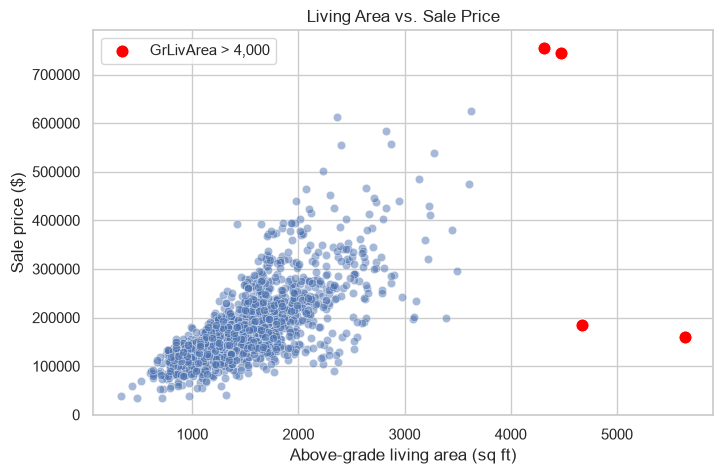

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=clean, x="GrLivArea", y="SalePrice", alpha=0.5, ax=ax)
sns.scatterplot(data=big, x="GrLivArea", y="SalePrice", color="red", s=90, ax=ax,
                label="GrLivArea > 4,000")
ax.set_title("Living Area vs. Sale Price")
ax.set_xlabel("Above-grade living area (sq ft)")
ax.set_ylabel("Sale price ($)")
plt.show()

We can see that two of the four extremely large houses sold for far less than their size suggests. Both have `SaleCondition = Partial`, which means the home was not completed when it was last assessed, so their low prices likely refelct a price for the incomplete house. The other two sold for prices that are reasonable for their size and quality ratings.

We decided to not delete anything, and instead add a flag column and check how much these rows affect our results. We can then later choose whether we want to exclude the two `Partial` rows.

In [14]:
clean["Outlier_LargePartial"] = ((clean["GrLivArea"] > 4000) &
                                 (clean["SaleCondition"] == "Partial")).astype(int)

r_all  = clean["GrLivArea"].corr(clean["SalePrice"])
r_drop = clean.loc[clean["Outlier_LargePartial"] == 0, "GrLivArea"].corr(
         clean.loc[clean["Outlier_LargePartial"] == 0, "SalePrice"])
print(f"Correlation GrLivArea vs SalePrice, all rows:           {r_all:.3f}")
print(f"Correlation GrLivArea vs SalePrice, without 2 outliers: {r_drop:.3f}")

Correlation GrLivArea vs SalePrice, all rows:           0.709
Correlation GrLivArea vs SalePrice, without 2 outliers: 0.735


Removing the two rows raises the correlation from roughly 0.71 to 0.74. That is a slight, but real shift. For now, we keep them in `clean`, but we now have flagged them.